# Supplementary Fig S1 · The entries outside the blocks are mostly near zero

Justifies the block-diagonal layout (cited from the Results overview). Breast only; A and B (user, 3 Nov: the niche-mean full-vs-blocks histogram was dropped as repetitive).

* **A** breast, the largest niche: its mean correlation matrix in the niche's gene order, whole (left) and the
  block-diagonal part that d_B uses (right).
* **B** breast, every index tile: its mean |r| over the gene pairs inside blocks and over those between blocks (the
  entries d_B leaves out), one value per tile; histogram over the 1,840 index tiles (after
  HS_notebooks/dag_vs_true_le_distance.ipynb, Part G; user, 3 Nov). Pairs with a gene without counts in the tile are
  left out (their correlation is undefined).

Correlations of the shrunk covariances; seed-0 layout.

**Run first:** `R10_block_structure` (`results/block_structure/tile_means.csv`, `niche_example.npz`).
Writes `figures/figS1_block/`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import style as ps

FIG = "figS1_block"
RES = ROOT / "results" / "block_structure"
BLOCKS, FULL = ps.TIER_COLORS["spindle"], ps.MUTED
CMAP = "RdBu_r"
H = 58.0


means = pd.read_csv(RES / "tile_means.csv")
ex = np.load(RES / "niche_example.npz")
print(sorted(set(means.tag)))


['method-v2']


## A · Breast, the largest niche: mean correlation matrix and its block-diagonal part

figures/figS1_block/panels/A.pdf/.png: 78 x 58 mm, 0.2 / 0.3 MB


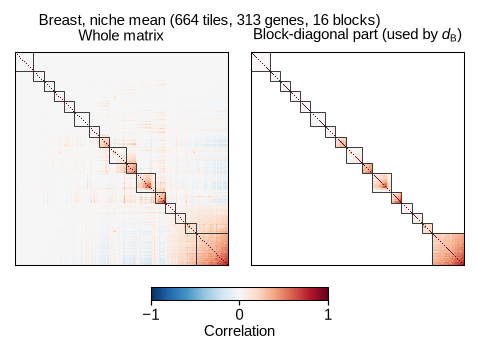

In [2]:
def panel_a(fig):
    C, runs = ex["corr"].astype(float), ex["runs"]
    p = len(C)
    mask = np.zeros_like(C, bool)
    for s, e in runs:
        mask[s:e, s:e] = True
    W, Hp = ps.size_mm(fig)
    side = 36.0
    for j, (M, title) in enumerate(((C, "Whole matrix"), (np.where(mask, C, np.nan), "Block-diagonal part (used by $d_{\\mathcal{B}}$)"))):
        x = 1.0 + j * (side + 4.0)
        ax = fig.add_axes([x / W, 1 - (7.0 + side) / Hp, side / W, side / Hp])
        ax.imshow(M, cmap=CMAP, vmin=-1, vmax=1, interpolation="nearest")
        for s, e in runs:
            ax.add_patch(Rectangle((s - 0.5, s - 0.5), e - s, e - s, fill=False, lw=0.4, ec=ps.INK))
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(True); sp.set_linewidth(0.5)
        fig.text((x + side / 2) / W, 1 - 5.5 / Hp, title, ha="center", va="bottom", fontsize=ps.TICK_PT)
    fig.text(5.0 / W, 1 - 0.5 / Hp, f"Breast, niche mean ({int(ex['n_tiles']):,} tiles, {p} genes, {len(runs)} blocks)",
             va="top", fontsize=ps.TICK_PT)
    cax = fig.add_axes([24.0 / W, 1 - (7.0 + side + 6.0) / Hp, 30.0 / W, 2.2 / Hp])
    cb = fig.colorbar(ScalarMappable(Normalize(-1, 1), CMAP), cax=cax, orientation="horizontal", ticks=[-1, 0, 1])
    cb.outline.set_linewidth(0.5)
    cb.set_label("Correlation", fontsize=ps.TICK_PT, labelpad=1)


fig = ps.panel(78, H); panel_a(fig); ps.save_panel(fig, FIG, "A")

## B · Breast, every index tile: mean |r| within and between blocks

breast, 1840 index tiles: within 0.184 +- 0.042, between 0.058 +- 0.014; within > between in 100 % of tiles
figures/figS1_block/panels/B.pdf/.png: 56 x 58 mm, 0.0 / 0.2 MB


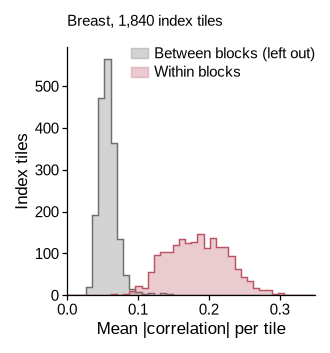

In [3]:
def panel_b(fig):
    ax = ps.axes(fig, left=12.0, right=2.0, bottom=10.0, top=6.0)
    m = means[means.key == "breast_cancer"]
    edges = np.linspace(0, np.ceil(m[["mean_within", "mean_between"]].max().max() * 20) / 20, 41)
    handles = []
    for part, color, label in (("between", FULL, "Between blocks (left out)"), ("within", BLOCKS, "Within blocks")):
        n, _ = np.histogram(m[f"mean_{part}"], edges)
        ax.stairs(n, edges, fill=True, color=color, alpha=0.3, lw=0)
        ax.stairs(n, edges, color=color, lw=0.7)
        handles.append(Patch(fc=color, alpha=0.3, ec=color, lw=0.7, label=label))
    print(f"breast, {len(m)} index tiles: within {m.mean_within.mean():.3f} +- {m.mean_within.std():.3f}, "
          f"between {m.mean_between.mean():.3f} +- {m.mean_between.std():.3f}; "
          f"within > between in {100 * (m.mean_within > m.mean_between).mean():.0f} % of tiles")
    ax.set_xlim(0, edges[-1])
    ax.set_ylim(0, None)
    ax.set_xlabel("Mean |correlation| per tile")
    ax.set_ylabel("Index tiles")
    ax.legend(handles=handles, loc="upper right")
    W, Hp = ps.size_mm(fig)
    fig.text(12.0 / W, 1 - 0.5 / Hp, f"Breast, {len(m):,} index tiles", va="top", fontsize=ps.TICK_PT)


fig = ps.panel(56, H); panel_b(fig); ps.save_panel(fig, FIG, "B")

## Full figure

breast, 1840 index tiles: within 0.184 +- 0.042, between 0.058 +- 0.014; within > between in 100 % of tiles
figures/figS1_block/figS1_block.pdf/.png: 136 x 58 mm, 0.2 / 0.6 MB


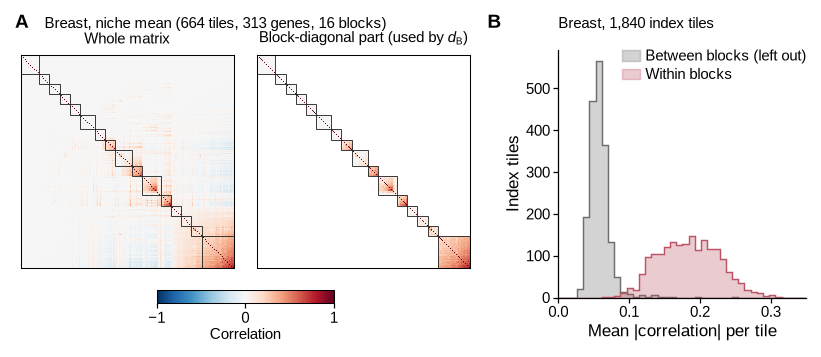

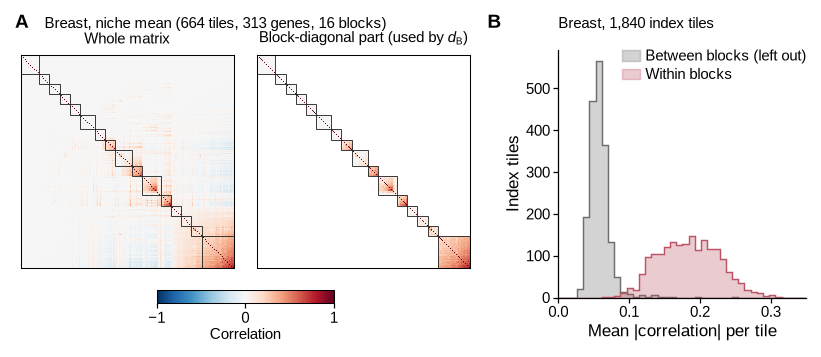

In [4]:
page = ps.page(136, H)
panel_a(ps.place(page, "A", 0, 0, 78, H))
panel_b(ps.place(page, "B", 80, 0, 56, H))
ps.save_figure(page, FIG)
page